# Assignment Beta, Question 1: SaafHawa model choice (API vs self hosting)

**Hafsa Rashid, 23K-0064, Agentic AI (AI4015), Fall 2026**

This notebook has every calculation for Section 2. All model figures were collected on **8 November 2026** and each one has a source tag (S1, S2, ...) that matches the reference list in my report.

Order of the notebook:
1. My parameters
2. Model data (Section 1 table in raw form)
3. Token volume per query and per month
4. API cost with and without prompt caching
5. Peak load and rate limits
6. Self hosting memory (gpt-oss-120b on an H100)
7. Latency budget (uses my measured tool latency log)
8. Break even analysis and the cost plot

In [1]:
import math, json, os
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Parameters

Roll number 23K-0064. R is the last two digits, D is the digit sum mod 10 (letters and hyphen ignored).

In [2]:
roll_digits = [2, 3, 0, 0, 6, 4]
R = 64
D = sum(roll_digits) % 10          # 15 mod 10 = 5

Q = 1500 + 25 * R                  # normal daily queries
N = 5 + (R % 4)                    # LLM calls per query (first attempt)
p = 0.04 + 0.01 * D                # tool call failure probability
H = 4 + (R % 4)                    # heatwave days per month
B = 1200 + 10 * R                  # monthly budget in USD
T = 10 - (R % 3)                   # latency target in seconds

print(f"R = {R}, D = {sum(roll_digits)} mod 10 = {D}")
print(f"Q = 1500 + 25*{R} = {Q}")
print(f"N = 5 + ({R} mod 4) = 5 + {R % 4} = {N}")
print(f"p = 0.04 + 0.01*{D} = {p:.2f}")
print(f"H = 4 + ({R} mod 4) = {H}")
print(f"B = 1200 + 10*{R} = ${B}")
print(f"T = 10 - ({R} mod 3) = 10 - {R % 3} = {T} s")

R = 64, D = 15 mod 10 = 5
Q = 1500 + 25*64 = 3100
N = 5 + (64 mod 4) = 5 + 0 = 5
p = 0.04 + 0.01*5 = 0.09
H = 4 + (64 mod 4) = 4
B = 1200 + 10*64 = $1840
T = 10 - (64 mod 3) = 10 - 1 = 9 s


## 2. Model data

Settings: every model runs in its non reasoning mode, or its lowest reasoning setting if it cannot switch reasoning off.
For the models that still think at their lowest setting, I estimate reasoning tokens per call from Artificial Analysis
measurements: `reasoning tokens = (time to first answer token - plain TTFT) x output speed`. Where AA gives no plain TTFT
for that model, I use 1.0 s as the plain TTFT (close to what the non reasoning models in the table show).

Prices are USD per 1M tokens. For open weight models the price is the cheapest public provider I could find.
`write_mult` is the cache write premium (OpenAI 30 min write = 1.25x, Anthropic 5 min write = 1.25x, others no premium).
`ttl_min` is how long a cache entry lives without traffic. `None` means the provider gives no cache discount.

In [3]:
models = [
 # closed source
 dict(name="GPT-6 Luna", provider="OpenAI", kind="closed", setting="reasoning effort = none",
      p_in=0.10, p_cache=0.01, write_mult=1.25, p_out=0.50, min_cache=1024, ttl_min=30,
      ttft=1.03, ttfat=1.03, speed=86.0, tool_score=48.0, tool_bench="AutomationBench-AA (high effort)",
      rpm=5000, tpm=2_000_000, src="S1,S2,S3,S4"),
 dict(name="GPT-6.1 Terra", provider="OpenAI", kind="closed", setting="reasoning effort = none",
      p_in=1.00, p_cache=0.05, write_mult=1.25, p_out=5.00, min_cache=1024, ttl_min=30,
      ttft=1.75, ttfat=1.75, speed=90.7, tool_score=50.3, tool_bench="Terminal-Bench 4.0 (vendor)",
      rpm=5000, tpm=2_000_000, src="S1,S3,S5,S6"),
 dict(name="Claude Haiku 5.5", provider="Anthropic", kind="closed", setting="effort = low",
      p_in=0.10, p_cache=0.01, write_mult=1.25, p_out=0.50, min_cache=512, ttl_min=5,
      ttft=None, ttfat=7.98, speed=137.8, tool_score=29.0, tool_bench="AutomationBench-AA (medium effort)",
      rpm=1000, tpm=500_000, src="S7,S3,S8,S9,S10"),
 dict(name="Claude Sonnet 5.5", provider="Anthropic", kind="closed", setting="effort = low",
      p_in=2.00, p_cache=0.10, write_mult=1.25, p_out=10.00, min_cache=512, ttl_min=5,
      ttft=None, ttfat=3.28, speed=109.6, tool_score=70.6, tool_bench="Terminal-Bench 4.0 (vendor)",
      rpm=1000, tpm=500_000, src="S7,S3,S11,S6,S10"),
 dict(name="Gemini 3.8 Flash", provider="Google", kind="closed", setting="thinking = low",
      p_in=0.75, p_cache=0.075, write_mult=1.0, p_out=3.75, min_cache=1024, ttl_min=5,
      ttft=0.78, ttfat=2.60, speed=265.3, tool_score=50.7, tool_bench="AutomationBench-AA",
      rpm=1000, tpm=2_000_000, src="S12,S3,S13,S14,S15"),
 dict(name="Gemini 3.5 Flash-Lite", provider="Google", kind="closed", setting="lowest thinking",
      p_in=0.30, p_cache=0.03, write_mult=1.0, p_out=2.50, min_cache=1024, ttl_min=5,
      ttft=None, ttfat=4.46, speed=161.0, tool_score=32.7, tool_bench="AutomationBench-AA",
      rpm=4000, tpm=4_000_000, src="S16,S3,S17,S18,S15"),
 dict(name="Grok 4.7", provider="xAI", kind="closed", setting="reasoning = low",
      p_in=2.00, p_cache=0.50, write_mult=1.0, p_out=6.00, min_cache=None, ttl_min=5,
      ttft=None, ttfat=9.65, speed=78.0, tool_score=57.0, tool_bench="AutomationBench-AA (low)",
      rpm=150*48, tpm=50_000_000, src="S19,S3,S20,S21"),
 # open weight (cheapest public provider)
 dict(name="DeepSeek V4.1 Flash", provider="DeepSeek API", kind="open", setting="non thinking",
      p_in=0.30, p_cache=0.006, write_mult=1.0, p_out=1.20, min_cache=64, ttl_min=60,
      ttft=1.33, ttfat=1.33, speed=269.4, tool_score=68.9, tool_bench="AutomationBench-AA (max effort)",
      rpm=None, tpm=None, src="S22,S3,S23,S24"),
 dict(name="Qwen3.8 27B", provider="Alibaba Cloud", kind="open", setting="non thinking",
      p_in=0.50, p_cache=0.10, write_mult=1.0, p_out=3.00, min_cache=None, ttl_min=5,
      ttft=5.30, ttfat=5.30, speed=41.0, tool_score=12.0, tool_bench="AutomationBench-AA (non reasoning)",
      rpm=None, tpm=None, src="S25,S26"),
 dict(name="GLM-5.3-Flash", provider="Z.ai API", kind="open", setting="thinking disabled",
      p_in=0.15, p_cache=0.03, write_mult=1.0, p_out=0.50, min_cache=None, ttl_min=5,
      ttft=3.53, ttfat=3.53, speed=56.0, tool_score=60.0, tool_bench="AutomationBench-AA",
      rpm=None, tpm=None, src="S27,S28"),
 dict(name="Mistral Small 4", provider="Mistral API", kind="open", setting="reasoning off",
      p_in=0.15, p_cache=0.015, write_mult=1.0, p_out=0.60, min_cache=None, ttl_min=5,
      ttft=1.77, ttfat=1.77, speed=127.0, tool_score=1.0, tool_bench="AutomationBench-AA",
      rpm=None, tpm=None, src="S29,S30"),
 dict(name="gpt-oss-120b", provider="CoreWeave", kind="open", setting="reasoning = low",
      p_in=0.03, p_cache=None, write_mult=1.0, p_out=0.17, min_cache=None, ttl_min=None,
      ttft=1.32, ttfat=2.42, speed=158.0, tool_score=0.2, tool_bench="AutomationBench-AA (high)",
      rpm=None, tpm=None, src="S29,S31,S32"),
 dict(name="Gemma 4 31B", provider="DeepInfra (FP8)", kind="open", setting="thinking off",
      p_in=0.13, p_cache=None, write_mult=1.0, p_out=0.38, min_cache=None, ttl_min=None,
      ttft=4.04, ttfat=4.04, speed=52.0, tool_score=76.9, tool_bench="tau2-bench avg (vendor)",
      rpm=None, tpm=None, src="S33,S34,S35"),
]

PLAIN_TTFT_DEFAULT = 1.0
for m in models:
    base = m["ttft"] if m["ttft"] is not None else PLAIN_TTFT_DEFAULT
    m["reason_tok"] = round(max(0.0, m["ttfat"] - base) * m["speed"])

df = pd.DataFrame(models)
df[["name", "provider", "setting", "p_in", "p_cache", "p_out", "ttfat", "speed", "reason_tok", "tool_score", "tool_bench"]]

,name,provider,setting,p_in,p_cache,p_out,ttfat,speed,reason_tok,tool_score,tool_bench
0,GPT-6 Luna,OpenAI,reasoning effort = none,0.10,0.010,0.50,1.03,86.0,0,48.0,AutomationBench-AA (high effort)
1,GPT-6.1 Terra,OpenAI,reasoning effort = none,1.00,0.050,5.00,1.75,90.7,0,50.3,Terminal-Bench 4.0 (vendor)
2,Claude Haiku 5.5,Anthropic,effort = low,0.10,0.010,0.50,7.98,137.8,962,29.0,AutomationBench-AA (medium effort)
3,Claude Sonnet 5.5,Anthropic,effort = low,2.00,0.100,10.00,3.28,109.6,250,70.6,Terminal-Bench 4.0 (vendor)
4,Gemini 3.8 Flash,Google,thinking = low,0.75,0.075,3.75,2.60,265.3,483,50.7,AutomationBench-AA
5,Gemini 3.5 Flash-Lite,Google,lowest thinking,0.30,0.030,2.50,4.46,161.0,557,32.7,AutomationBench-AA
6,Grok 4.7,xAI,reasoning = low,2.00,0.500,6.00,9.65,78.0,675,57.0,AutomationBench-AA (low)
7,DeepSeek V4.1 Flash,DeepSeek API,non thinking,0.30,0.006,1.20,1.33,269.4,0,68.9,AutomationBench-AA (max effort)
8,Qwen3.8 27B,Alibaba Cloud,non thinking,0.50,0.100,3.00,5.30,41.0,0,12.0,AutomationBench-AA (non reasoning)
9,GLM-5.3-Flash,Z.ai API,thinking disabled,0.15,0.030,0.50,3.53,56.0,0,60.0,AutomationBench-AA


## 3. Token volume

For call k (k = 1 ... N): input = 2000 + 800(k - 1). Calls 1 to N-1 give 350 output tokens, call N gives 600.
Each of calls 1 to N-1 fails with probability p and is repeated once with the same input (and again 350 output tokens).

In [4]:
inputs  = [2000 + 800 * (k - 1) for k in range(1, N + 1)]
outputs = [350] * (N - 1) + [600]
for k in range(N):
    print(f"call {k+1}: input {inputs[k]:,}  output {outputs[k]}")

in_first   = sum(inputs)
out_first  = sum(outputs)
in_retry   = p * sum(inputs[:-1])          # only calls 1..N-1 can be retried
out_retry  = p * 350 * (N - 1)
calls_per_q = N + p * (N - 1)

E_in  = in_first + in_retry
E_out = out_first + out_retry
print()
print(f"first attempt input  = {in_first:,}")
print(f"expected retry input = {p} x {sum(inputs[:-1]):,} = {in_retry:,.0f}")
print(f"expected input per query  = {E_in:,.0f} tokens")
print(f"first attempt output = {out_first:,}")
print(f"expected retry output = {p} x 350 x {N-1} = {out_retry:,.0f}")
print(f"expected output per query = {E_out:,.0f} tokens")
print(f"expected LLM calls per query = {N} + {p} x {N-1} = {calls_per_q:.2f}")

call 1: input 2,000  output 350
call 2: input 2,800  output 350
call 3: input 3,600  output 350
call 4: input 4,400  output 350
call 5: input 5,200  output 600

first attempt input  = 18,000
expected retry input = 0.09 x 12,800 = 1,152
expected input per query  = 19,152 tokens
first attempt output = 2,000
expected retry output = 0.09 x 350 x 4 = 126
expected output per query = 2,126 tokens
expected LLM calls per query = 5 + 0.09 x 4 = 5.36


In [5]:
normal_days = 30 - H
monthly_queries = normal_days * Q + H * 5 * Q
monthly_in  = monthly_queries * E_in
monthly_out = monthly_queries * E_out
monthly_calls = monthly_queries * calls_per_q

print(f"monthly queries = {normal_days} x {Q:,} + {H} x 5 x {Q:,} = {monthly_queries:,}")
print(f"monthly input tokens  = {monthly_queries:,} x {E_in:,.0f} = {monthly_in:,.0f}  ({monthly_in/1e9:.3f} B)")
print(f"monthly output tokens = {monthly_queries:,} x {E_out:,.0f} = {monthly_out:,.0f}  ({monthly_out/1e6:.1f} M)")
print(f"monthly LLM calls     = {monthly_calls:,.0f}")

monthly queries = 26 x 3,100 + 4 x 5 x 3,100 = 142,600
monthly input tokens  = 142,600 x 19,152 = 2,731,075,200  (2.731 B)
monthly output tokens = 142,600 x 2,126 = 303,167,600  (303.2 M)
monthly LLM calls     = 764,336


## 4. API cost per month

**Without caching:** all input at the normal input price, output at the output price (reasoning tokens added to output).

**With caching:** the first 1,500 tokens of every call are the same system prompt and tool schemas.
With about 2 queries per minute on a normal day and about 45 per minute in the heatwave window, the prefix stays warm, so almost every call reads it from cache.
To be safe I still charge one cache write per TTL window for the whole month (even at night), at the provider's write premium.
1,500 tokens is above every provider's minimum that I found, so caching applies wherever a discount exists.

In [6]:
PREFIX = 1500
MIN_PER_MONTH = 30 * 24 * 60

def monthly_cost(m, queries=monthly_queries, cache=True):
    calls = queries * calls_per_q
    out_tok = queries * E_out + calls * m["reason_tok"]
    in_tok = queries * E_in
    if not cache or m["p_cache"] is None or (m["min_cache"] and m["min_cache"] > PREFIX):
        return (in_tok * m["p_in"] + out_tok * m["p_out"]) / 1e6
    writes = MIN_PER_MONTH / m["ttl_min"]                 # one write per TTL window, all month
    write_tok = min(writes * PREFIX, calls * PREFIX)
    cached_tok = calls * PREFIX - write_tok
    uncached_tok = in_tok - calls * PREFIX
    cost = (uncached_tok * m["p_in"] + cached_tok * m["p_cache"]
            + write_tok * m["p_in"] * m["write_mult"] + out_tok * m["p_out"])
    return cost / 1e6

rows = []
for m in models:
    c0 = monthly_cost(m, cache=False)
    c1 = monthly_cost(m, cache=True)
    rows.append(dict(model=m["name"], kind=m["kind"], reasoning_tok_per_call=m["reason_tok"],
                     cost_no_cache=round(c0, 2), cost_cache=round(c1, 2),
                     saving_pct=round(100 * (c0 - c1) / c0, 1),
                     within_B_no_cache=c0 <= B, within_B_cache=c1 <= B))
cost_df = pd.DataFrame(rows).sort_values("cost_cache")
cost_df

,model,kind,reasoning_tok_per_call,cost_no_cache,cost_cache,saving_pct,within_B_no_cache,within_B_cache
11,gpt-oss-120b,open,174,156.08,156.08,0.0,True,True
0,GPT-6 Luna,closed,0,424.69,321.75,24.2,True,True
9,GLM-5.3-Flash,open,0,561.25,425.22,24.2,True,True
10,Mistral Small 4,open,0,591.56,438.53,25.9,True,True
12,Gemma 4 31B,open,0,470.24,470.24,0.0,True,True
2,Claude Haiku 5.5,closed,962,792.34,690.64,12.8,True,True
7,DeepSeek V4.1 Flash,open,0,1183.12,846.37,28.5,True,True
8,Qwen3.8 27B,open,0,2275.04,1821.62,19.9,False,True
5,Gemini 3.5 Flash-Lite,closed,557,2641.58,2335.52,11.6,False,False
1,GPT-6.1 Terra,closed,0,4246.91,3160.33,25.6,False,False


Worked example for one model so the steps are visible (GPT-6 Luna, with caching):

In [7]:
m = models[0]
calls = monthly_queries * calls_per_q
uncached = monthly_in - calls * PREFIX
writes = MIN_PER_MONTH / m["ttl_min"] * PREFIX
cached = calls * PREFIX - writes
print(f"cacheable tokens  = {calls:,.0f} calls x 1,500 = {calls*PREFIX:,.0f}")
print(f"cache writes      = {MIN_PER_MONTH/m['ttl_min']:,.0f} windows x 1,500 = {writes:,.0f} tokens at 1.25 x $0.10")
print(f"cache reads       = {cached:,.0f} tokens at $0.01")
print(f"uncached input    = {monthly_in:,.0f} - {calls*PREFIX:,.0f} = {uncached:,.0f} tokens at $0.10")
print(f"output            = {monthly_out:,.0f} tokens at $0.50")
total = (uncached*0.10 + cached*0.01 + writes*0.125 + monthly_out*0.50)/1e6
print(f"total = ${total:,.2f} per month")

cacheable tokens  = 764,336 calls x 1,500 = 1,146,504,000
cache writes      = 1,440 windows x 1,500 = 2,160,000 tokens at 1.25 x $0.10
cache reads       = 1,144,344,000 tokens at $0.01
uncached input    = 2,731,075,200 - 1,146,504,000 = 1,584,571,200 tokens at $0.10
output            = 303,167,600 tokens at $0.50
total = $321.75 per month


## 5. Peak load and rate limits

On a heatwave day traffic is 5Q and 35% of it lands between 12:00 and 14:00 (120 minutes).

In [8]:
peak_day = 5 * Q
peak_window_q = 0.35 * peak_day
peak_qpm = peak_window_q / 120
peak_rpm = peak_qpm * calls_per_q
peak_in_tpm = peak_qpm * E_in
peak_out_tpm = peak_qpm * E_out
uncached_per_q = E_in - calls_per_q * PREFIX
peak_uncached_tpm = peak_qpm * uncached_per_q

print(f"heatwave day queries = 5 x {Q:,} = {peak_day:,}")
print(f"queries in 12:00-14:00 = 0.35 x {peak_day:,} = {peak_window_q:,.0f}")
print(f"peak queries per minute = {peak_window_q:,.0f} / 120 = {peak_qpm:.2f}")
print(f"peak LLM requests per minute = {peak_qpm:.2f} x {calls_per_q:.2f} = {peak_rpm:.1f}")
print(f"peak input tokens per minute  = {peak_qpm:.2f} x {E_in:,.0f} = {peak_in_tpm:,.0f}")
print(f"peak output tokens per minute = {peak_qpm:.2f} x {E_out:,.0f} = {peak_out_tpm:,.0f}")
print(f"peak uncached input TPM (what Anthropic counts) = {peak_qpm:.2f} x {uncached_per_q:,.0f} = {peak_uncached_tpm:,.0f}")

heatwave day queries = 5 x 3,100 = 15,500
queries in 12:00-14:00 = 0.35 x 15,500 = 5,425
peak queries per minute = 5,425 / 120 = 45.21
peak LLM requests per minute = 45.21 x 5.36 = 242.3
peak input tokens per minute  = 45.21 x 19,152 = 865,830
peak output tokens per minute = 45.21 x 2,126 = 96,113
peak uncached input TPM (what Anthropic counts) = 45.21 x 11,112 = 502,355


In [9]:
rl = []
for m in models:
    out_tpm = peak_out_tpm + peak_rpm * m["reason_tok"]
    if m["rpm"] is None:
        rl.append(dict(model=m["name"], limit_rpm="not published", limit_tpm="not published", fits="unknown"))
        continue
    if m["provider"] == "Anthropic":
        need_tpm = peak_uncached_tpm          # input TPM limit, uncached only
    else:
        need_tpm = peak_in_tpm + out_tpm
    fits = (peak_rpm <= m["rpm"]) and (need_tpm <= m["tpm"])
    rl.append(dict(model=m["name"], need_rpm=round(peak_rpm), limit_rpm=m["rpm"],
                   need_tpm=round(need_tpm), limit_tpm=m["tpm"], fits=fits))
pd.DataFrame(rl)

,model,need_rpm,limit_rpm,need_tpm,limit_tpm,fits
0,GPT-6 Luna,242.0,5000,961943.0,2000000,True
1,GPT-6.1 Terra,242.0,5000,961943.0,2000000,True
2,Claude Haiku 5.5,242.0,1000,502355.0,500000,False
3,Claude Sonnet 5.5,242.0,1000,502355.0,500000,False
4,Gemini 3.8 Flash,242.0,1000,1078982.0,2000000,True
5,Gemini 3.5 Flash-Lite,242.0,4000,1096913.0,4000000,True
6,Grok 4.7,242.0,7200,1125507.0,50000000,True
7,DeepSeek V4.1 Flash,NaN,not published,NaN,not published,unknown
8,Qwen3.8 27B,NaN,not published,NaN,not published,unknown
9,GLM-5.3-Flash,NaN,not published,NaN,not published,unknown


## 6. Self hosting memory: gpt-oss-120b

I picked gpt-oss-120b because it is one of my open weight models, Apache 2.0, and is designed to fit on one 80 GB GPU.
Its attention is **not** plain full attention: the 36 layers alternate between sliding window attention (window 128 tokens) and full attention, with grouped query attention (64 query heads, 8 KV heads, head_dim 64).
So I adapt the KV formula: the 18 full layers store KV for the whole sequence, the 18 sliding layers store at most 128 tokens.

Values from config.json (screenshot in the report): num_hidden_layers = 36, num_key_value_heads = 8, head_dim = 64, sliding_window = 128, layer_types alternate sliding/full.

In [10]:
params_total = 117e9        # model card: 117B total, 5.1B active
layers, kv_heads, head_dim, window = 36, 8, 64, 128
full_layers = layers // 2
sliding_layers = layers - full_layers
bytes_per_value = 2         # FP16 KV cache

w_fp16 = params_total * 2 / 1e9
w_int8 = params_total * 1 / 1e9
w_int4 = params_total * 0.5 / 1e9
print(f"weights FP16  = 117e9 x 2 bytes   = {w_fp16:.1f} GB")
print(f"weights 8-bit = 117e9 x 1 byte    = {w_int8:.1f} GB")
print(f"weights 4-bit = 117e9 x 0.5 byte  = {w_int4:.1f} GB")

gpt_oss = next(m for m in models if m["name"] == "gpt-oss-120b")
longest = inputs[-1] + outputs[-1] + gpt_oss["reason_tok"]   # last call: 5,200 in + 600 out + reasoning
print(f"longest sequence = {inputs[-1]:,} + {outputs[-1]} + {gpt_oss['reason_tok']} reasoning = {longest:,} tokens")

kv_standard = 2 * layers * kv_heads * head_dim * longest * bytes_per_value
kv_adapted = 2 * kv_heads * head_dim * bytes_per_value * (full_layers * longest + sliding_layers * min(longest, window))
print(f"KV (formula as given, all 36 layers full) = 2 x 36 x 8 x 64 x {longest:,} x 2 = {kv_standard/1e9:.3f} GB")
print(f"KV (adapted: 18 full + 18 sliding)        = 2 x 8 x 64 x 2 x (18 x {longest:,} + 18 x {window}) = {kv_adapted/1e9:.3f} GB")

weights FP16  = 117e9 x 2 bytes   = 234.0 GB
weights 8-bit = 117e9 x 1 byte    = 117.0 GB
weights 4-bit = 117e9 x 0.5 byte  = 58.5 GB
longest sequence = 5,200 + 600 + 174 reasoning = 5,974 tokens
KV (formula as given, all 36 layers full) = 2 x 36 x 8 x 64 x 5,974 x 2 = 0.440 GB
KV (adapted: 18 full + 18 sliding)        = 2 x 8 x 64 x 2 x (18 x 5,974 + 18 x 128) = 0.225 GB


In [11]:
gpu_name, gpu_mem_gb = "NVIDIA H100 SXM 80GB", 80
usable = 0.9 * gpu_mem_gb
free_for_kv = usable - w_int4
max_seq = math.floor(free_for_kv * 1e9 / kv_adapted)
max_seq_std = math.floor(free_for_kv * 1e9 / kv_standard)
print(f"usable memory = 0.9 x {gpu_mem_gb} = {usable:.1f} GB")
print(f"left for KV   = {usable:.1f} - {w_int4:.1f} = {free_for_kv:.1f} GB")
print(f"max concurrent sequences (adapted KV) = floor({free_for_kv:.1f} GB / {kv_adapted/1e9:.4f} GB) = {max_seq}")
print(f"(if every layer were full attention it would be {max_seq_std})")

usable memory = 0.9 x 80 = 72.0 GB
left for KV   = 72.0 - 58.5 = 13.5 GB
max concurrent sequences (adapted KV) = floor(13.5 GB / 0.2249 GB) = 60
(if every layer were full attention it would be 30)


## 7. Latency budget

Per LLM call I use: time to first answer token (TTFAT, includes any thinking) + answer tokens / output speed.
Calls run one after another, and each tool call adds the median tool latency I measured.
Expected retry delay = p x (sum of the latency of calls 1 to N-1), because a failed call is simply run again.

The tool delay comes from `tool_latency_log.csv` (made by `tool_latency.py`). If the log is missing, a clearly marked placeholder is used.

In [12]:
LOG = "tool_latency_log.csv"
PLACEHOLDER = 0.50
if os.path.exists(LOG):
    log = pd.read_csv(LOG)
    ok = log[log.status == "ok"]
    tool_delay = ok.latency_s.median()
    days_measured = sorted(ok.date.unique())
    print("measurements per tool:")
    print(ok.groupby("tool").latency_s.agg(["count", "median", "mean"]))
    print(f"days measured: {days_measured}")
    print(f"pooled median of all measurements = {tool_delay:.4f} s  (this is the delay used for every tool call)")
    api_only = ok[ok.tool.isin(["air_quality_openaq", "weather_openmeteo"])].latency_s.median()
    print(f"median of the two network APIs only = {api_only:.4f} s (sensitivity check)")
    delay_source = "measured"
else:
    tool_delay = PLACEHOLDER
    api_only = PLACEHOLDER
    days_measured = []
    delay_source = "PLACEHOLDER"
    print(f"No log found. Using PLACEHOLDER tool delay = {PLACEHOLDER} s. Run tool_latency.py on two days and re-run.")

measurements per tool:
                    count    median      mean
tool                                         
air_quality_openaq     24  1.193772  1.479213
heat_index_local       24  0.000002  0.000004
kb_lookup_local        24  0.000027  0.000029
weather_openmeteo      24  1.030239  1.487244
days measured: ['2026-11-09', '2026-11-10']
pooled median of all measurements = 0.3049 s  (this is the delay used for every tool call)
median of the two network APIs only = 1.1742 s (sensitivity check)


In [13]:
def call_time(m, out_tokens):
    return m["ttfat"] + out_tokens / m["speed"]

def latency_original(m, d):
    llm = sum(call_time(m, o) for o in outputs)
    tools = (N - 1) * d
    retry = p * sum(call_time(m, o) for o in outputs[:-1])
    return llm, tools, retry, llm + tools + retry

def latency_fanout(m, d):
    # change: one planning call issues all independent tools at once
    # (air quality, weather + heat index computed in code, knowledge base), then one answer call
    plan = call_time(m, 350)
    answer = call_time(m, 600)
    retry = p * plan
    return plan + answer, d, retry, plan + answer + d + retry

lat = []
for m in models:
    a = latency_original(m, tool_delay)
    b = latency_fanout(m, tool_delay)
    lat.append(dict(model=m["name"], llm_s=round(a[0], 2), tools_s=round(a[1], 2), retry_s=round(a[2], 2),
                    total_s=round(a[3], 2), meets_T=a[3] <= T,
                    fanout_total_s=round(b[3], 2), fanout_meets_T=b[3] <= T))
lat_df = pd.DataFrame(lat)
lat_df

,model,llm_s,tools_s,retry_s,total_s,meets_T,fanout_total_s,fanout_meets_T
0,GPT-6 Luna,28.41,1.22,1.84,31.46,False,13.87,False
1,GPT-6.1 Terra,30.80,1.22,2.02,34.04,False,14.78,False
2,Claude Haiku 5.5,54.41,1.22,3.79,59.42,False,24.11,False
3,Claude Sonnet 5.5,34.65,1.22,2.33,38.20,False,16.12,False
4,Gemini 3.8 Flash,20.54,1.22,1.41,23.17,False,9.44,False
5,Gemini 3.5 Flash-Lite,34.72,1.22,2.39,38.33,False,15.72,False
6,Grok 4.7,73.89,1.22,5.09,80.20,False,33.06,False
7,DeepSeek V4.1 Flash,14.07,1.22,0.95,16.24,False,6.73,True
8,Qwen3.8 27B,75.28,1.22,4.98,81.48,False,35.32,False
9,GLM-5.3-Flash,53.36,1.22,3.52,58.10,False,25.21,False


### Choosing my two strongest candidates

Rule: must stay within the budget with caching and support native tool calling. Then I rank by **AutomationBench-AA**, because it is the one tool use benchmark that Artificial Analysis ran the same way on most of my models (Zapier style multi app tool workflows). I do not mix in vendor numbers from other benchmarks (for example Gemma's tau2-bench) because those are not comparable.

In [14]:
merged = cost_df.merge(lat_df, on="model").merge(df[["name", "tool_score", "tool_bench"]], left_on="model", right_on="name")
cands = merged[merged.within_B_cache & merged.tool_bench.str.startswith("AutomationBench")].sort_values("tool_score", ascending=False)
cands[["model", "cost_cache", "tool_score", "tool_bench", "total_s", "fanout_total_s"]].head(6)

,model,cost_cache,tool_score,tool_bench,total_s,fanout_total_s
6,DeepSeek V4.1 Flash,846.37,68.9,AutomationBench-AA (max effort),16.24,6.73
2,GLM-5.3-Flash,425.22,60.0,AutomationBench-AA,58.10,25.21
1,GPT-6 Luna,321.75,48.0,AutomationBench-AA (high effort),31.46,13.87
5,Claude Haiku 5.5,690.64,29.0,AutomationBench-AA (medium effort),59.42,24.11
7,Qwen3.8 27B,1821.62,12.0,AutomationBench-AA (non reasoning),81.48,35.32
3,Mistral Small 4,438.53,1.0,AutomationBench-AA,27.45,11.73


In [15]:
top2 = cands.head(2).model.tolist()
print("two strongest candidates:", top2)
for name in top2:
    m = next(x for x in models if x["name"] == name)
    llm, tools, retry, tot = latency_original(m, tool_delay)
    print(f"\n{name}")
    for k in range(N):
        print(f"  call {k+1}: {m['ttfat']:.2f} + {outputs[k]}/{m['speed']} = {call_time(m, outputs[k]):.2f} s")
    print(f"  tools: {N-1} x {tool_delay:.3f} = {tools:.2f} s")
    print(f"  retries: {p} x {sum(call_time(m, o) for o in outputs[:-1]):.2f} = {retry:.2f} s")
    print(f"  total = {tot:.2f} s  (target {T} s) -> {'meets' if tot <= T else 'misses'} T")
    llm2, tools2, retry2, tot2 = latency_fanout(m, tool_delay)
    print(f"  after fan-out change: {call_time(m,350):.2f} + {call_time(m,600):.2f} + {tools2:.3f} + {retry2:.2f} = {tot2:.2f} s -> {'meets' if tot2 <= T else 'misses'} T")

two strongest candidates: ['DeepSeek V4.1 Flash', 'GLM-5.3-Flash']

DeepSeek V4.1 Flash
  call 1: 1.33 + 350/269.4 = 2.63 s
  call 2: 1.33 + 350/269.4 = 2.63 s
  call 3: 1.33 + 350/269.4 = 2.63 s
  call 4: 1.33 + 350/269.4 = 2.63 s
  call 5: 1.33 + 600/269.4 = 3.56 s
  tools: 4 x 0.305 = 1.22 s
  retries: 0.09 x 10.52 = 0.95 s
  total = 16.24 s  (target 9 s) -> misses T
  after fan-out change: 2.63 + 3.56 + 0.305 + 0.24 = 6.73 s -> meets T

GLM-5.3-Flash
  call 1: 3.53 + 350/56.0 = 9.78 s
  call 2: 3.53 + 350/56.0 = 9.78 s
  call 3: 3.53 + 350/56.0 = 9.78 s
  call 4: 3.53 + 350/56.0 = 9.78 s
  call 5: 3.53 + 600/56.0 = 14.24 s
  tools: 4 x 0.305 = 1.22 s
  retries: 0.09 x 39.12 = 3.52 s
  total = 58.10 s  (target 9 s) -> misses T
  after fan-out change: 9.78 + 14.24 + 0.305 + 0.88 = 25.21 s -> misses T


## 8. Break even: self hosting vs the API

Self hosting cost is a step function. One GPU can hold `max_seq` sequences at once, and we size for the heatwave peak.
Concurrent sequences at peak (Little's law) = peak queries per second x seconds each query stays in the system.
For the self hosted latency I use the measured Artificial Analysis speed for gpt-oss-120b (low) and the same fan-out design.
Every GPU is paid for the whole 30 day month (720 hours).

In [16]:
gpu_price_hr = 2.69          # RunPod Secure Cloud H100 SXM, on demand (S36)
gpu_month = gpu_price_hr * 24 * 30

self_lat = latency_fanout(gpt_oss, tool_delay)[3]

def peak_concurrency(q):
    return (5 * q * 0.35 / 120 / 60) * self_lat

def gpus_needed(q):
    return max(1, math.ceil(peak_concurrency(q) / max_seq))

def self_cost(q):
    return gpus_needed(q) * gpu_month

print(f"GPU month = {gpu_price_hr} x 720 h = ${gpu_month:,.2f}")
print(f"self hosted latency per query (fan-out design) = {self_lat:.2f} s")
print(f"peak concurrency at Q={Q}: {peak_concurrency(Q):.1f} sequences -> {gpus_needed(Q)} GPU(s)")
print(f"one GPU covers up to Q = {max_seq / ((5*0.35/120/60) * self_lat):,.0f} queries/day")

GPU month = 2.69 x 720 h = $1,936.80
self hosted latency per query (fan-out design) = 11.57 s
peak concurrency at Q=3100: 8.7 sequences -> 1 GPU(s)
one GPU covers up to Q = 21,327 queries/day


In [17]:
# candidates that meet T after the change; if none, take the lower latency one
fan = {name: latency_fanout(next(x for x in models if x["name"] == name), tool_delay)[3] for name in top2}
meeting = [n for n in top2 if fan[n] <= T]
if meeting:
    ref_name = min(meeting, key=lambda n: monthly_cost(next(x for x in models if x["name"] == n)))
else:
    ref_name = min(top2, key=lambda n: fan[n])
ref = next(x for x in models if x["name"] == ref_name)
api_per_query = monthly_cost(ref) / monthly_queries
print(f"reference API model: {ref_name}, cost per query = ${api_per_query:.5f}")

def api_cost(q):
    return api_per_query * ((30 - H) * q + H * 5 * q)

q_star = None
for q in range(100, 300001, 10):
    if self_cost(q) < api_cost(q):
        q_star = q
        break
print(f"Q* = {q_star:,} queries per day" if q_star else "self hosting never gets cheaper in the scanned range")
if q_star:
    print(f"at Q*: API ${api_cost(q_star):,.0f} vs self hosting ${self_cost(q_star):,.0f} ({gpus_needed(q_star)} GPU)")
    print(f"Q* / current Q = {q_star / Q:.2f}x")

reference API model: DeepSeek V4.1 Flash, cost per query = $0.00594
Q* = 7,100 queries per day
at Q*: API $1,938 vs self hosting $1,937 (1 GPU)
Q* / current Q = 2.29x


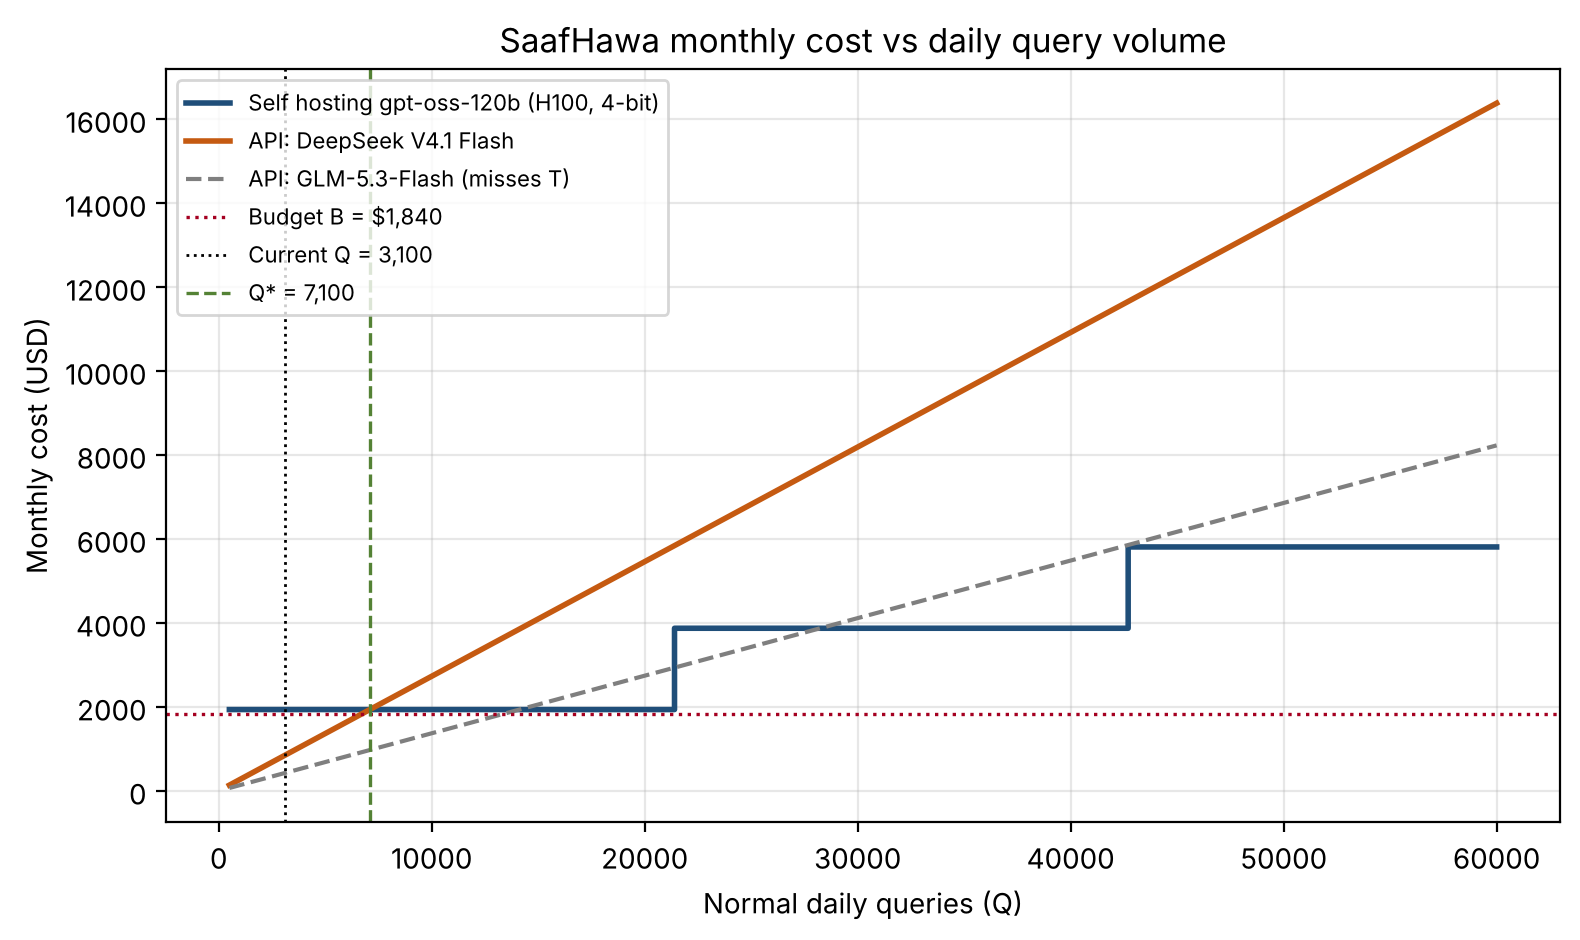

In [18]:
qs = list(range(500, 60001, 100))
cheap = min((x for x in models if x["name"] in top2), key=lambda m: monthly_cost(m))
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.step(qs, [self_cost(q) for q in qs], where="post", label="Self hosting gpt-oss-120b (H100, 4-bit)", color="#1f4e79", lw=2)
ax.plot(qs, [api_cost(q) for q in qs], label=f"API: {ref_name}", color="#c55a11", lw=2)
other = [n for n in top2 if n != ref_name]
if other:
    om = next(x for x in models if x["name"] == other[0])
    opq = monthly_cost(om) / monthly_queries
    ax.plot(qs, [opq * 46 * q for q in qs], label=f"API: {other[0]} (misses T)", color="#7f7f7f", lw=1.5, ls="--")
ax.axhline(B, color="#a50021", ls=":", lw=1.2, label=f"Budget B = ${B:,}")
ax.axvline(Q, color="black", ls=":", lw=1, label=f"Current Q = {Q:,}")
if q_star:
    ax.axvline(q_star, color="#548235", ls="--", lw=1.2, label=f"Q* = {q_star:,}")
ax.set_xlabel("Normal daily queries (Q)")
ax.set_ylabel("Monthly cost (USD)")
ax.set_title("SaafHawa monthly cost vs daily query volume")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig("cost_vs_volume.png", dpi=200)
plt.show()

In [19]:
# save everything the report needs
results = dict(
    R=R, D=D, Q=Q, N=N, p=p, H=H, B=B, T=T,
    inputs=inputs, outputs=outputs, E_in=E_in, E_out=E_out, calls_per_q=calls_per_q,
    monthly_queries=monthly_queries, monthly_in=monthly_in, monthly_out=monthly_out,
    peak_qpm=peak_qpm, peak_rpm=peak_rpm, peak_in_tpm=peak_in_tpm, peak_out_tpm=peak_out_tpm,
    peak_uncached_tpm=peak_uncached_tpm,
    cost_table=cost_df.to_dict("records"), rl_table=rl, lat_table=lat_df.to_dict("records"),
    models=models,
    w_fp16=w_fp16, w_int8=w_int8, w_int4=w_int4, longest=longest,
    kv_standard_gb=kv_standard/1e9, kv_adapted_gb=kv_adapted/1e9, usable=usable, free_for_kv=free_for_kv,
    max_seq=max_seq, max_seq_std=max_seq_std, gpu_month=gpu_month, gpu_price_hr=gpu_price_hr,
    self_lat=self_lat, peak_conc=peak_concurrency(Q), gpus_now=gpus_needed(Q),
    q_per_gpu=max_seq / ((5*0.35/120/60) * self_lat),
    top2=top2, ref_name=ref_name, api_per_query=api_per_query, q_star=q_star,
    tool_delay=float(tool_delay), api_only=float(api_only),
    ref_fanout_api=latency_fanout(ref, api_only)[3], ref_orig_api=latency_original(ref, api_only)[3], delay_source=delay_source,
    days_measured=list(map(str, days_measured)),
)
json.dump(results, open("results.json", "w"), indent=1, default=float)
print("saved results.json and cost_vs_volume.png")

saved results.json and cost_vs_volume.png
